# How reliable is off-the-shelf sentiment analysis? Replies to two politicians' tweets
**Data.** 5,328 public replies to tweets by **@JoeBiden** (2,540) and **@realDonaldTrump** (2,788), collected around December 2020.

**Privacy and terms.** Tweet text and user handles are **not** published: X/Twitter's terms allow sharing tweet IDs, not content. Text was scored locally (`scripts/score_replies.py`) and only de-identified numeric features are stored in `data/reply_scores.csv`, shuffled so rows cannot be matched back to the source.

**Question.** This is a *methods* study, not a statement about either politician. Do two popular lexicon tools, **TextBlob** and **VADER**, agree, and what do their scores really measure on short, sarcastic, political text? The sample is whatever the collector scraped, so it says nothing about public opinion at large.

In [1]:
import warnings, pathlib
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
pd.set_option("display.precision", 3); pd.set_option("display.width", 160)
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG = pathlib.Path("images"); IMG.mkdir(exist_ok=True)
from textblob import TextBlob
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from sklearn.metrics import cohen_kappa_score, confusion_matrix
s = pd.read_csv("data/reply_scores.csv")
print(s.shape); s.groupby("replied_to")[["n_words", "has_url", "n_exclaim", "caps_share"]].mean().round(3)

(5328, 15)


,n_words,has_url,n_exclaim,caps_share
replied_to,,,,
@JoeBiden,10.933,0.469,0.283,0.031
@realDonaldTrump,10.962,0.445,0.323,0.056


## The tools disagree more than people assume

In [2]:
lab = lambda x, eps: np.select([x > eps, x < -eps], ["positive", "negative"], "neutral")
s["tb_label"] = lab(s.textblob_polarity, 0.0); s["vd_label"] = lab(s.vader_compound, 0.05)   # VADER's recommended +/-0.05 band
order = ["negative", "neutral", "positive"]
cm = pd.DataFrame(confusion_matrix(s.vd_label, s.tb_label, labels=order), index=[f"VADER {o}" for o in order], columns=[f"TextBlob {o}" for o in order])
agree = (s.tb_label == s.vd_label).mean(); kappa = cohen_kappa_score(s.tb_label, s.vd_label)
opp = ((s.tb_label == "positive") & (s.vd_label == "negative") | (s.tb_label == "negative") & (s.vd_label == "positive")).mean()
print(f"label agreement {agree:.1%}, Cohen's kappa {kappa:.2f}; opposite polarity {opp:.1%}; Pearson r of scores {s.textblob_polarity.corr(s.vader_compound):.2f}")
both_zero = ((s.textblob_polarity == 0) & (s.vader_compound == 0)).mean()
print(f"replies with no sentiment-bearing words for either tool: {both_zero:.1%}")
cm

label agreement 58.3%, Cohen's kappa 0.36; opposite polarity 10.0%; Pearson r of scores 0.42
replies with no sentiment-bearing words for either tool: 31.2%


,TextBlob negative,TextBlob neutral,TextBlob positive
VADER negative,679,765,366
VADER neutral,157,1682,242
VADER positive,168,526,743


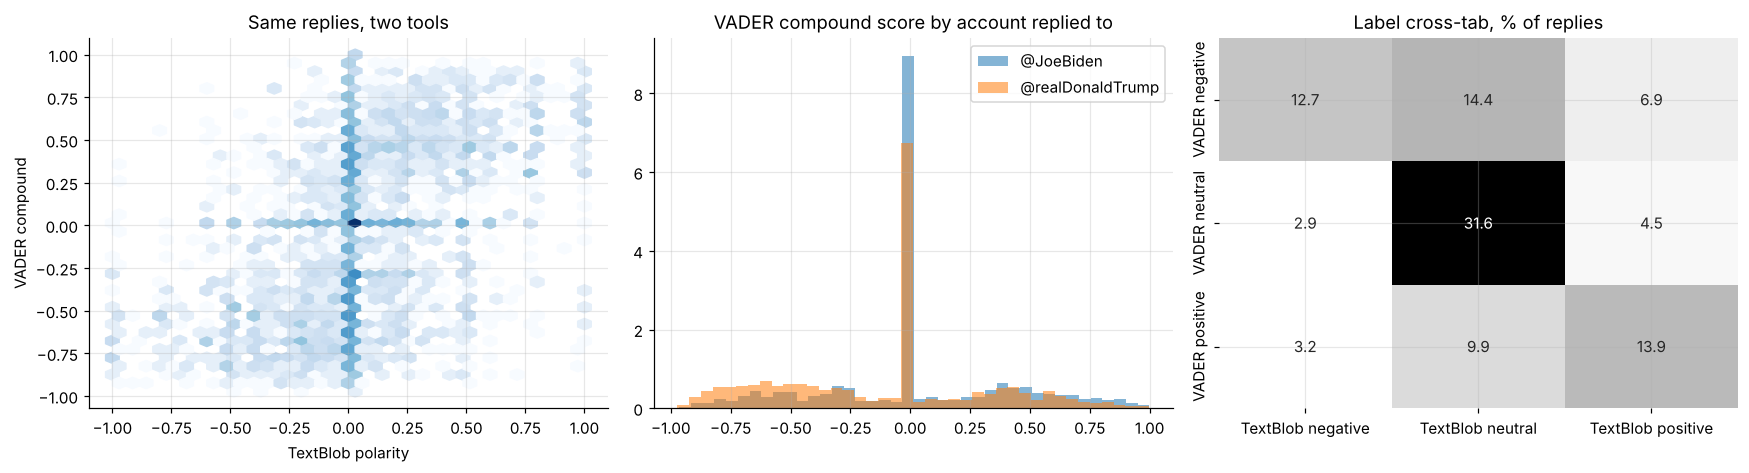

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
axes[0].hexbin(s.textblob_polarity, s.vader_compound, gridsize=35, cmap="Blues", bins="log")
axes[0].set_xlabel("TextBlob polarity"); axes[0].set_ylabel("VADER compound"); axes[0].set_title("Same replies, two tools")
for acc, g in s.groupby("replied_to"):
    axes[1].hist(g.vader_compound, bins=40, alpha=.55, density=True, label=acc)
axes[1].set_title("VADER compound score by account replied to"); axes[1].legend()
sns.heatmap(cm / cm.values.sum() * 100, annot=True, fmt=".1f", cmap="Greys", cbar=False, ax=axes[2]); axes[2].set_title("Label cross-tab, % of replies")
plt.tight_layout(); plt.savefig(IMG / "tool_agreement.png", bbox_inches="tight"); plt.show()

## Group comparison with honest uncertainty
Bootstrap 95% intervals for the mean score and the share labelled negative, under each tool.

In [4]:
rng = np.random.default_rng(0)
def boot(x, f, n=2000):
    x = np.asarray(x); stats_ = [f(x[rng.integers(0, len(x), len(x))]) for _ in range(n)]
    return f(x), *np.percentile(stats_, [2.5, 97.5])
rows = []
for acc, g in s.groupby("replied_to"):
    for name, col, eps in [("TextBlob", "textblob_polarity", 0.0), ("VADER", "vader_compound", 0.05)]:
        m, lo, hi = boot(g[col], np.mean); n_, nlo, nhi = boot(g[col], lambda v: np.mean(v < -eps))
        rows.append({"replied_to": acc, "tool": name, "mean": m, "mean_ci": f"[{lo:.3f}, {hi:.3f}]", "share_negative": n_, "neg_ci": f"[{nlo:.3f}, {nhi:.3f}]"})
comp = pd.DataFrame(rows).set_index(["tool", "replied_to"]); comp.round(3)

,,mean,mean_ci,share_negative,neg_ci
tool,replied_to,,,,
TextBlob,@JoeBiden,0.039,"[0.029, 0.049]",0.160,"[0.146, 0.175]"
VADER,@JoeBiden,0.024,"[0.009, 0.038]",0.256,"[0.238, 0.272]"
TextBlob,@realDonaldTrump,0.027,"[0.015, 0.038]",0.214,"[0.199, 0.230]"
VADER,@realDonaldTrump,-0.107,"[-0.123, -0.091]",0.416,"[0.398, 0.435]"


## Why: what lexicons can and cannot see
Invented examples (not real tweets) show the typical failure modes on this kind of text.

In [5]:
V = SentimentIntensityAnalyzer()
ex = ["Great job, another brilliant idea. Truly genius.",            # sarcasm
      "This is not good at all.",                                     # negation
      "I can't wait for January!!!",                                  # ambiguous, depends on the speaker
      "Prayers for everyone affected by the storm.",                  # sympathy read as negative
      "LOL ok",                                                       # slang / no lexicon words
      "Lower taxes and more jobs, that is what we need."]
pd.DataFrame({"text (invented)": ex, "TextBlob": [round(TextBlob(e).sentiment.polarity, 2) for e in ex],
              "VADER": [V.polarity_scores(e)["compound"] for e in ex]})

,text (invented),TextBlob,VADER
0,"Great job, another brilliant idea. Truly genius.",0.85,0.896
1,This is not good at all.,-0.35,-0.341
2,I can't wait for January!!!,0.00,0.000
3,Prayers for everyone affected by the storm.,0.00,-0.153
4,LOL ok,0.65,0.694
5,"Lower taxes and more jobs, that is what we need.",0.50,-0.296


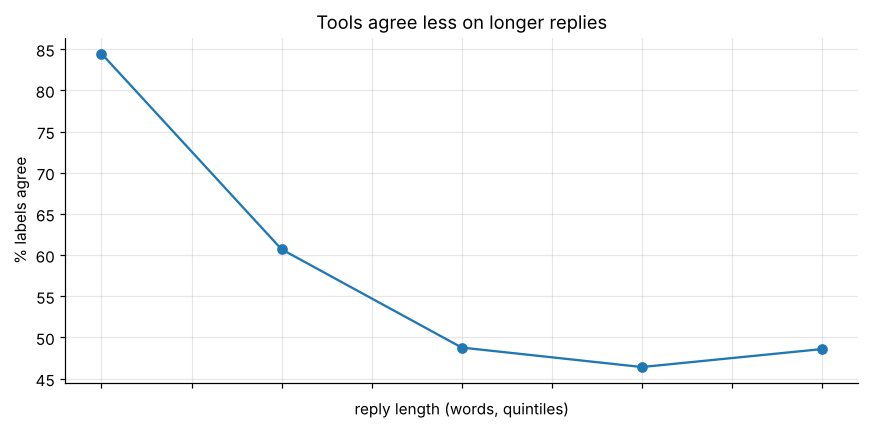

{Interval(-0.001, 3.0, closed='right'): 0.845, Interval(3.0, 8.0, closed='right'): 0.607, Interval(8.0, 14.0, closed='right'): 0.488, Interval(14.0, 18.0, closed='right'): 0.464, Interval(18.0, 49.0, closed='right'): 0.486}


In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
q = pd.qcut(s.n_words, 5, duplicates="drop")
s.groupby(q, observed=True).apply(lambda g: (g.tb_label == g.vd_label).mean() * 100).plot(marker="o", ax=ax)
ax.set_xlabel("reply length (words, quintiles)"); ax.set_ylabel("% labels agree"); ax.set_title("Tools agree less on longer replies")
ax.set_xticklabels([]); plt.tight_layout(); plt.savefig(IMG / "agreement_by_length.png", bbox_inches="tight"); plt.show()
print(s.groupby(q, observed=True).apply(lambda g: (g.tb_label == g.vd_label).mean()).round(3).to_dict())

## Findings
* **Two standard tools agree on only 58% of replies** (Cohen's κ = 0.36, "fair"). On 10% of replies they give *opposite* polarity, and their scores correlate at just r = 0.42. 31% of replies contain no word either lexicon recognises, so they are scored neutral by default.
* **The conclusion depends on the tool.** With TextBlob, replies to the two accounts look similar (mean polarity 0.039 vs 0.027; 16% vs 21% negative). With VADER, replies to @realDonaldTrump look markedly more negative (mean −0.107 vs 0.024; 42% vs 26% negative). Both differences are "significant" by bootstrap, yet they tell different stories. That is a measurement problem, not a finding about either politician or their audience.
* **Agreement falls as text gets longer:** 85% for replies of 1-3 words (mostly both neutral) and about 46-49% beyond 8 words, where sarcasm, quotation and mixed sentiment are common. The invented examples show sarcasm scored as strongly positive by both tools and policy statements scored in opposite directions.
* **What a sound study would do:** hand-label a few hundred replies, measure each tool's accuracy against those labels (or fine-tune a transformer model on them), and report uncertainty. A lexicon score on political Twitter text should not be read as public opinion.